# Explainable AI for Predicting Late Delivery in E-Commerce Shipping
**Rohan Kunapalli — IEEE BigData 2026 High School Symposium, paper SP19216**

This notebook is the whole study in one place: every analysis in the paper, in order, with its output printed underneath.
It is a simplified version of the full `ieee_bigdata_research` project and gives **the same numbers**.

The original notebook was lost with a stolen laptop. This version was rebuilt from the paper's methods section.
Using `random_state=42` reproduces the paper's Table III exactly, which tells us the original used the same seed.

**Run it:** put `Train.csv` in the same folder (or let cell 1 download it), then *Run All*. Takes about 1–2 minutes.

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from interpret.glassbox import ExplainableBoostingClassifier
import shap
from lime.lime_tabular import LimeTabularExplainer

SEED = 42   # used for the split and every model

## 1. Load the dataset
Kaggle *E-Commerce Shipping Data* (Gopalani). Target `Reached.on.Time_Y.N`: **1 = late, 0 = on time**.

In [2]:
import os
URL = "https://raw.githubusercontent.com/jeeniagogoi1/Ecommerce-Shipping-Prediction/main/Train.csv"
df = pd.read_csv("Train.csv" if os.path.exists("Train.csv") else URL, encoding="utf-8-sig")

TARGET = "Reached.on.Time_Y.N"
print("Rows, columns:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Late shipments:", (df[TARGET] == 1).sum(), f"({(df[TARGET] == 1).mean():.1%})")
df.head()

Rows, columns: (10999, 12)
Missing values: 0
Late shipments: 6563 (59.7%)


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


## 2. Prepare the data
1. Drop `ID` (just a row number) → **10 predictors** remain.
2. One-hot encode the 4 text columns (each category becomes its own 0/1 column) → **19 columns**.
3. Stratified 80/20 split (keeps the same late/on-time ratio in both parts).
4. Scale the 6 number columns to [0, 1], **fitting the scaler on training data only** so the test set never influences training.

In [3]:
CATEGORICAL = ["Warehouse_block", "Mode_of_Shipment", "Product_importance", "Gender"]
NUMERIC = ["Customer_care_calls", "Customer_rating", "Cost_of_the_Product",
           "Prior_purchases", "Discount_offered", "Weight_in_gms"]

y = df[TARGET]
X = pd.get_dummies(df.drop(columns=["ID", TARGET]), columns=CATEGORICAL, dtype=float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

scaler = MinMaxScaler()
X_train[NUMERIC] = scaler.fit_transform(X_train[NUMERIC])
X_test[NUMERIC] = scaler.transform(X_test[NUMERIC])

cols = list(X.columns)
print("Encoded columns:", len(cols))
print("Train / test rows:", len(X_train), "/", len(X_test))

Encoded columns: 19
Train / test rows: 8799 / 2200


## 3. Train the five models
- **Main models:** XGBoost, LightGBM, EBM.
- **Baselines:** Logistic Regression, Decision Tree (depth 5).

XGBoost uses the Table II settings that the original 15-candidate, 3-fold random search selected.
(That search's list of options was never recorded, so the search itself can't be rerun.)

In [4]:
models = {
    "XGBoost (tuned)": XGBClassifier(n_estimators=150, max_depth=5, learning_rate=0.05,
                                     subsample=0.8, colsample_bytree=0.6,
                                     eval_metric="logloss", random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=200, num_leaves=31, learning_rate=0.05,
                               min_child_samples=20, feature_fraction=0.8,
                               random_state=SEED, verbose=-1),
    "EBM (interpretable)": ExplainableBoostingClassifier(max_bins=128, random_state=SEED),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree (depth 5)": DecisionTreeClassifier(max_depth=5, random_state=SEED),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print("trained", name)

xgb = models["XGBoost (tuned)"]
ebm = models["EBM (interpretable)"]

trained XGBoost (tuned)


trained LightGBM


trained EBM (interpretable)
trained Logistic Regression
trained Decision Tree (depth 5)


## 4. Table III — test-set performance
- **ROC-AUC:** chance the model ranks a random late shipment above a random on-time one (0.5 = guessing).
- **Accuracy:** share classified correctly at the 0.5 cutoff.
- **F1:** balance of precision and recall for the *late* class.

In [5]:
rows = []
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, p),
                 "Accuracy": accuracy_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "% predicted late": pred.mean()})
table3 = pd.DataFrame(rows)
table3.round(3)

,Model,ROC-AUC,Accuracy,F1,% predicted late
0,XGBoost (tuned),0.740,0.671,0.663,0.379
1,LightGBM,0.742,0.661,0.666,0.420
2,EBM (interpretable),0.740,0.671,0.664,0.383
3,Logistic Regression,0.719,0.638,0.689,0.569
4,Decision Tree (depth 5),0.736,0.680,0.640,0.295


Logistic Regression predicts "late" most often, so it catches more true late shipments (higher F1) but also flags more on-time ones (lower accuracy).

## 5. SHAP — how much each feature pushes each prediction
TreeSHAP gives every feature a contribution (in log-odds) for every test shipment. Importance = average absolute contribution over all 2,200 test shipments.

In [6]:
shap_values = shap.TreeExplainer(xgb).shap_values(X_test)
shap_imp = pd.Series(np.abs(shap_values).mean(axis=0), index=cols).sort_values(ascending=False)
shap_imp.head(8).round(4)

Discount_offered             1.3105
Weight_in_gms                0.6151
Prior_purchases              0.1400
Cost_of_the_Product          0.1087
Customer_rating              0.0477
Customer_care_calls          0.0430
Product_importance_medium    0.0250
Product_importance_high      0.0177
dtype: float32

## 6. LIME — explaining one shipment at a time
LIME makes 500 random variations of a shipment, sees how the XGBoost prediction changes, and fits a simple linear model to that.
Global importance = average absolute LIME weight over 30 random test shipments.

In [7]:
def predict_fn(arr):
    return xgb.predict_proba(pd.DataFrame(arr, columns=cols))

def lime_weights(explainer, row):
    exp = explainer.explain_instance(row, predict_fn, num_features=len(cols), num_samples=500)
    return dict(exp.as_map()[1])     # {column index: weight} for the "late" class

def new_explainer(seed):
    return LimeTabularExplainer(X_train.values, feature_names=cols,
                                class_names=["On time", "Late"], mode="classification",
                                random_state=seed)

explainer = new_explainer(42)
idx30 = np.random.default_rng(42).choice(len(X_test), size=30, replace=False)
W = np.zeros((30, len(cols)))
for r, i in enumerate(idx30):
    for c, w in lime_weights(explainer, X_test.values[i]).items():
        W[r, c] = abs(w)
lime_imp = pd.Series(W.mean(axis=0), index=cols).sort_values(ascending=False)
lime_imp.head(8).round(4)

Weight_in_gms              0.1763
Discount_offered           0.1752
Prior_purchases            0.0333
Mode_of_Shipment_Flight    0.0258
Product_importance_high    0.0244
Cost_of_the_Product        0.0233
Mode_of_Shipment_Road      0.0227
Warehouse_block_D          0.0211
dtype: float64

## 7. EBM importance and Table IV
The EBM explains itself: its importance comes straight from the trained model. Each one-hot column is ranked on its own.

In [8]:
names = list(ebm.term_names_)
ebm_imp = pd.Series(ebm.term_importances(), index=names)
ebm_imp = ebm_imp[[n for n in names if " & " not in n]].sort_values(ascending=False)  # main effects only

table4 = pd.DataFrame({
    "SHAP rank": shap_imp.rank(ascending=False).astype(int),
    "EBM rank": ebm_imp.rank(ascending=False).astype(int),
    "LIME rank": lime_imp.rank(ascending=False).astype(int),
}).sort_values("SHAP rank")
table4.head(8)

,SHAP rank,EBM rank,LIME rank
Discount_offered,1,1,2
Weight_in_gms,2,2,1
Prior_purchases,3,3,3
Cost_of_the_Product,4,4,6
Customer_rating,5,6,15
Customer_care_calls,6,5,12
Product_importance_medium,7,8,11
Product_importance_high,8,7,5


## 8. Table VI — EBM shape functions
Each curve shows how one feature adds to or subtracts from the late-delivery log-odds. Bin edges are converted back to original units.

Discount_offered: max +6.91 at 63.5-65, min -2.02 at 2.5-3.5
Weight_in_gms: max +2.20 at 2056-2170, min -0.74 at 4596-4622
Customer_care_calls: max +0.08 at 2-2.5, min -0.20 at 6.5-7


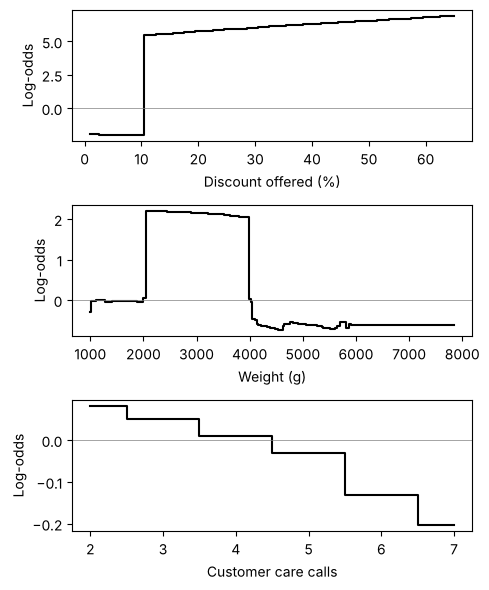

In [9]:
def shape(feature):
    d = ebm.explain_global().data(names.index(feature))
    i = NUMERIC.index(feature)
    edges = np.array(d["names"], dtype=float) * scaler.data_range_[i] + scaler.data_min_[i]
    return edges, np.array(d["scores"])

fig, axes = plt.subplots(3, 1, figsize=(5, 6))
for ax, (f, label) in zip(axes, [("Discount_offered", "Discount offered (%)"),
                                 ("Weight_in_gms", "Weight (g)"),
                                 ("Customer_care_calls", "Customer care calls")]):
    edges, scores = shape(f)
    ax.step(edges, np.append(scores, scores[-1]), where="post", color="black")
    ax.axhline(0, color="grey", lw=0.5); ax.set_xlabel(label); ax.set_ylabel("Log-odds")
    j_max, j_min = scores.argmax(), scores.argmin()
    print(f"{f}: max {scores[j_max]:+.2f} at {edges[j_max]:.4g}-{edges[j_max+1]:.4g}, "
          f"min {scores[j_min]:+.2f} at {edges[j_min]:.4g}-{edges[j_min+1]:.4g}")
plt.tight_layout(); plt.show()

The raw data confirms what the curves show: the discount effect is a cliff at about 10%, and weight has a 2,000–4,000 g plateau.

In [10]:
late = df[TARGET]
for label, mask in [("Discount <= 10%", df.Discount_offered <= 10),
                    ("Discount  > 10%", df.Discount_offered > 10),
                    ("Weight 1000-1999 g", df.Weight_in_gms < 2000),
                    ("Weight 2000-3999 g", df.Weight_in_gms.between(2000, 3999)),
                    ("Weight 4000+ g", df.Weight_in_gms >= 4000)]:
    print(f"{label:20s} n={mask.sum():5d}  late={late[mask].mean():6.1%}")

Discount <= 10%      n= 8352  late= 46.9%
Discount  > 10%      n= 2647  late=100.0%
Weight 1000-1999 g   n= 3241  late= 67.8%
Weight 2000-3999 g   n= 1790  late= 99.9%
Weight 4000+ g       n= 5968  late= 43.2%


## 9. Table V — explanation stability
Pick 15 test shipments. Explain each one 5 times with different random seeds and keep the top-5 features each time.
Compare every pair of runs with the **Jaccard score** = shared features ÷ all distinct features
(5 shared = 1.00, 4 = 0.67, 3 = 0.43, 2 = 0.25).

Only the explanation is repeated. The model and split never change.

In [11]:
def top5(weights):  # weights: {column index: value}
    return sorted(weights, key=lambda c: abs(weights[c]), reverse=True)[:5]

def jaccard(a, b):
    return len(set(a) & set(b)) / len(set(a) | set(b))

idx15 = np.random.default_rng(43).choice(len(X_test), size=15, replace=False)
scores = {"SHAP": [], "LIME": []}
for i in idx15:
    runs = {"SHAP": [], "LIME": []}
    for seed in [0, 1, 2, 3, 4]:
        runs["LIME"].append(top5(lime_weights(new_explainer(seed), X_test.values[i])))
        sv = shap.TreeExplainer(xgb).shap_values(X_test.iloc[[i]])[0]
        runs["SHAP"].append(top5(dict(enumerate(sv))))
    for method in runs:
        scores[method].append(np.mean([jaccard(a, b) for a, b in combinations(runs[method], 2)]))

table5 = pd.DataFrame({m: {"Mean": np.mean(s), "Std Dev": np.std(s, ddof=1),
                           "Min": np.min(s), "Max": np.max(s)} for m, s in scores.items()}).T
table5.round(2)

,Mean,Std Dev,Min,Max
SHAP,1.00,0.00,1.00,1.00
LIME,0.37,0.04,0.29,0.42


TreeSHAP uses no random numbers, so SHAP's 1.00 is guaranteed for a fixed trained model. LIME's score changes because its 500 samples are random.

## 10. Gender attribution — Welch's t-test
Compare |SHAP| of the `Gender_F` column between shipments that were **actually** late and **actually** on time.
Welch's t-test checks whether the difference in averages is bigger than chance, without assuming equal spread in the two groups.

In [12]:
g = np.abs(shap_values[:, cols.index("Gender_F")])
late_grp, ontime_grp = g[y_test.values == 1], g[y_test.values == 0]
t, p = stats.ttest_ind(late_grp, ontime_grp, equal_var=False)
gap = abs(late_grp.mean() - ontime_grp.mean())

print(f"mean |SHAP| late    = {late_grp.mean():.4f}  (n={len(late_grp)})")
print(f"mean |SHAP| on time = {ontime_grp.mean():.4f}  (n={len(ontime_grp)})")
print(f"t = {t:.2f},  p = {p:.1e}")
print(f"Gap = {gap:.4f} log-odds = {100 * gap / shap_imp.iloc[0]:.2f}% of Discount_offered's importance")

mean |SHAP| late    = 0.0082  (n=1313)
mean |SHAP| on time = 0.0098  (n=887)
t = -5.23,  p = 1.9e-07
Gap = 0.0016 log-odds = 0.12% of Discount_offered's importance


Statistically significant, but very small in size. It shows the model's *use* of the gender column differs slightly between outcome groups.
It does not compare how female and male customers are treated, so on its own it is not evidence of discrimination.

## 11. Paper vs this notebook

In [13]:
print("Table III (paper: XGB .740/67.1%/.663, LGBM .742/66.1%/.666, EBM .740/67.1%/.664,")
print("           LR .719/63.8%/.689, DT .736/68.0%/.640)")
print(table3[["Model", "ROC-AUC", "Accuracy", "F1"]].round(3).to_string(index=False))
print(f"\nSHAP Discount / Weight: {shap_imp['Discount_offered']:.2f} / {shap_imp['Weight_in_gms']:.2f}  (paper 1.31 / 0.62)")
print(f"Gender t-test: t = {t:.2f}  (paper -5.23)")
print(f"LIME stability: {table5.loc['LIME','Mean']:.2f} +/- {table5.loc['LIME','Std Dev']:.2f}"
      f"  -> replaces the paper's 0.40 +/- 0.04 (original LIME seeds were lost)")

Table III (paper: XGB .740/67.1%/.663, LGBM .742/66.1%/.666, EBM .740/67.1%/.664,
           LR .719/63.8%/.689, DT .736/68.0%/.640)
                  Model  ROC-AUC  Accuracy    F1
        XGBoost (tuned)    0.740     0.671 0.663
               LightGBM    0.742     0.661 0.666
    EBM (interpretable)    0.740     0.671 0.664
    Logistic Regression    0.719     0.638 0.689
Decision Tree (depth 5)    0.736     0.680 0.640

SHAP Discount / Weight: 1.31 / 0.62  (paper 1.31 / 0.62)
Gender t-test: t = -5.23  (paper -5.23)
LIME stability: 0.37 +/- 0.04  -> replaces the paper's 0.40 +/- 0.04 (original LIME seeds were lost)
